<h1>Machine Learning Pipeline<h1>

<h5> 1. Define the application </h5>
<h5> 2. Load data (smiles + target values)</h5>
<h5> 3. Explore and clean data  </h5>
<h5> 4. Featurize molecules / scaling (descriptors / fingerprints) </h5>
<h5> 5. Split data (training and test set) </h5>
<h5> 6. Choose and build ML model (classification / regression) </h5>
<h5> 7. Train model on training set </h5>
<h5> 8. Evaluate model on test set </h5>
<h5> 9. Improve model (optimization, hyperparamater tuning, etc) </h5>
<h5> 10. Save, Load, Use model for predictions on new data </h5>
<h5> 11. Optional: Deploy model </h5>


In [ ]:
# Install RDKIT
!pip install rdkit
# Import some RDKIT modules
from rdkit import Chem                   # the core module
from rdkit.Chem import Draw              # drawing molecules
from rdkit.Chem import Descriptors       # molecular descriptors (MW, LogP, etc)
from rdkit.Chem import AllChem           # fingerprints and more
from rdkit import DataStructs            # similarity (Tanimoto, etc)
from rdkit.Chem import PandasTools       # rdkit + Pandas
from rdkit.Chem import rdMolDescriptors  # more advances descriptors
from rdkit.Chem import Lipinski          # Lipinski's Rule of Five desc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 29.8 MB/s  0:00:01


In [ ]:
import pandas as pd
import numpy as np

<h1> 1 Define application <h1>

The goal of our model is to use a molecule’s SMILES string (X) to predict its aqueous solubility (y), expressed as LogS = log₁₀(solubility in mol/L).

X = SMILES  
y = LogS (= log₁₀(solubility in mol/L))  



<h1> 2 Load data <h1>

In [ ]:
# load data from github mcsorkun/AqSolDB
# Load only SMILES and Solubility (LogS = log10(solubility in mol/L))
import pandas as pd

url = "https://raw.githubusercontent.com/mcsorkun/AqSolDB/master/results/data_curated.csv"
df = pd.read_csv(url)
df = df[['SMILES', 'Solubility']]
df

,SMILES,Solubility
0,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127
1,O=C1Nc2cccc3cccc1c23,-3.254767
2,Clc1ccc(C=O)cc1,-2.177078
3,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924409
4,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662065
...,...,...
9977,C(c1ccc(cc1)NCCCC)(=O)OCCN(C)C,-3.010000
9978,OC1=C(C(C2=C(O)[C@@](C(C(C(N)=O)=C(O)[C@H]3N(C...,-2.930000
9979,c1(cc(ccc1C(C)C)C)O,-2.190000
9980,COc1ccc(CCN(C)CCCC(C#N)(C(C)C)c2ccc(OC)c(OC)c2...,-3.980000


<h1> 3 Explore and Clean data <h1>

In [ ]:
df.describe()

,Solubility
count,9982.000000
mean,-2.889909
std,2.368154
min,-13.171900
25%,-4.326325
50%,-2.618173
75%,-1.209735
max,2.137682


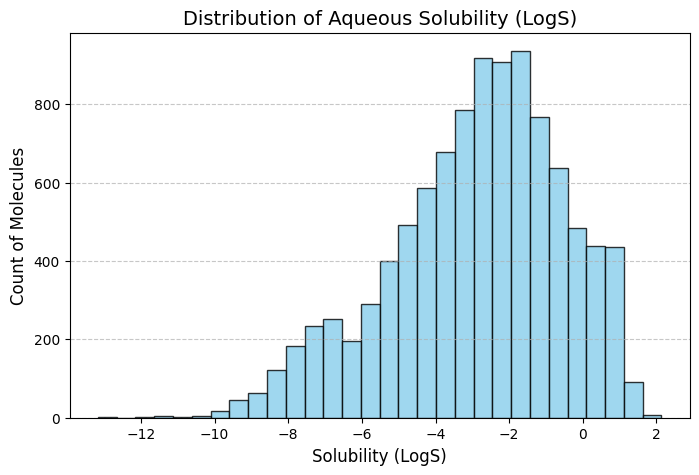

In [ ]:
import matplotlib.pyplot as plt

# Visualize the distribution of Solubility using only matplotlib
plt.figure(figsize=(8, 5))
plt.hist(df['Solubility'], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
plt.title('Distribution of Aqueous Solubility (LogS)', fontsize=14)
plt.xlabel('Solubility (LogS)', fontsize=12)
plt.ylabel('Count of Molecules', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Check for missing values
df.isnull().sum()

,0
SMILES,0
Solubility,0


In [ ]:
# Convert smiles to mol objects
df["mol"] = [Chem.MolFromSmiles(s) for s in df["SMILES"]]
df

,SMILES,Solubility,mol
0,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec3140>
1,O=C1Nc2cccc3cccc1c23,-3.254767,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec31b0>
2,Clc1ccc(C=O)cc1,-2.177078,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec13f0>
3,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924409,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0d60>
4,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662065,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0c10>
...,...,...,...
9977,C(c1ccc(cc1)NCCCC)(=O)OCCN(C)C,-3.010000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98270>
9978,OC1=C(C(C2=C(O)[C@@](C(C(C(N)=O)=C(O)[C@H]3N(C...,-2.930000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae982e0>
9979,c1(cc(ccc1C(C)C)C)O,-2.190000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98350>
9980,COc1ccc(CCN(C)CCCC(C#N)(C(C)C)c2ccc(OC)c(OC)c2...,-3.980000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae983c0>


In [ ]:
# Check for missing values
df.isnull().sum()

,0
SMILES,0
Solubility,0
mol,2


In [ ]:
# Remove invalid smiles (where mol = None)
df = df[df["mol"].notnull()].copy()

In [ ]:
# Convert smiles to canonical smiles
# by converting the mol objects back to smiles
canonical_smiles = []
for mol in df["mol"]:
    canonical_smiles.append(Chem.MolToSmiles(mol, canonical=True))
df["smiles_canonical"] = canonical_smiles
df

,SMILES,Solubility,mol,smiles_canonical
0,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec3140>,CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-]
1,O=C1Nc2cccc3cccc1c23,-3.254767,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec31b0>,O=C1Nc2cccc3cccc1c23
2,Clc1ccc(C=O)cc1,-2.177078,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec13f0>,O=Cc1ccc(Cl)cc1
3,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924409,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0d60>,CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...
4,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662065,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0c10>,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...
...,...,...,...,...
9977,C(c1ccc(cc1)NCCCC)(=O)OCCN(C)C,-3.010000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98270>,CCCCNc1ccc(C(=O)OCCN(C)C)cc1
9978,OC1=C(C(C2=C(O)[C@@](C(C(C(N)=O)=C(O)[C@H]3N(C...,-2.930000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae982e0>,CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C...
9979,c1(cc(ccc1C(C)C)C)O,-2.190000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98350>,Cc1ccc(C(C)C)c(O)c1
9980,COc1ccc(CCN(C)CCCC(C#N)(C(C)C)c2ccc(OC)c(OC)c2...,-3.980000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae983c0>,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...


In [ ]:
# number of duplicate canonical SMILES
df.duplicated(subset='smiles_canonical').sum()

np.int64(0)

In [ ]:
# Remove duplicate smiles_canonical
df = df.drop_duplicates(subset="smiles_canonical")
len(df)

9980

<h1> 4 Featurize molecules (descriptors / fingerprints) <h1>

In [ ]:
# add (meaningfull) descriptors
# Tip: use an LLM to come up with meaniningfull descriptors
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
from rdkit.Chem import rdmolops
from rdkit.Chem import MolSurf

df['MW'] = df['mol'].apply(Descriptors.MolWt)
df['MolLogP_Descriptor'] = df['mol'].apply(Descriptors.MolLogP)
df['TPSA'] = df['mol'].apply(Descriptors.TPSA)
df['NumHDonors'] = df['mol'].apply(Descriptors.NumHDonors)
df['NumHAcceptors'] = df['mol'].apply(Descriptors.NumHAcceptors)
df['NumRotatableBonds'] = df['mol'].apply(Descriptors.NumRotatableBonds)
df["FormalCharge"] = df["mol"].apply(rdmolops.GetFormalCharge)
df['NumRotatableBonds'] = df['mol'].apply(Descriptors.NumRotatableBonds)
df['NumAromaticRings'] = df['mol'].apply(Descriptors.NumAromaticRings)
df['NumSaturatedRings'] = df['mol'].apply(Descriptors.NumSaturatedRings)
df['NumAliphaticRings'] = df['mol'].apply(Descriptors.NumAliphaticRings)
df['MolMR'] = df['mol'].apply(Descriptors.MolMR)
df['HeavyAtomCount'] = df['mol'].apply(Descriptors.HeavyAtomCount)
df['NumRadicalElectrons'] = df['mol'].apply(Descriptors.NumRadicalElectrons)
df['NumAromaticFraction'] = df['mol'].apply(Lipinski.FractionCSP3)
df["PEOE_VSA6"] = df["mol"].apply(MolSurf.PEOE_VSA6)
#

df

,SMILES,Solubility,mol,smiles_canonical,MW,MolLogP_Descriptor,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,FormalCharge,NumAromaticRings,NumSaturatedRings,NumAliphaticRings,MolMR,HeavyAtomCount,NumRadicalElectrons,NumAromaticFraction,PEOE_VSA6
0,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec3140>,CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],392.510,3.95810,0.00,0,0,17,0,0,0,0,102.4454,23,0,1.000000,96.815240
1,O=C1Nc2cccc3cccc1c23,-3.254767,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec31b0>,O=C1Nc2cccc3cccc1c23,169.183,2.40550,29.10,1,1,0,0,2,0,1,51.9012,13,0,0.000000,24.265468
2,Clc1ccc(C=O)cc1,-2.177078,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec13f0>,O=Cc1ccc(Cl)cc1,140.569,2.15250,17.07,0,1,1,0,1,0,0,36.8395,9,0,0.000000,23.733674
3,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924409,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0d60>,CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,756.226,8.11610,120.72,2,6,10,0,6,0,0,200.7106,53,0,0.173913,161.155024
4,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662065,<rdkit.Chem.rdchem.Mol object at 0x7fe39aec0c10>,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,422.525,2.48540,56.60,0,6,12,0,2,4,4,119.0760,31,0,0.520000,24.265468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9977,C(c1ccc(cc1)NCCCC)(=O)OCCN(C)C,-3.010000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98270>,CCCCNc1ccc(C(=O)OCCN(C)C)cc1,264.369,2.61700,41.57,1,4,8,0,1,0,0,78.6762,19,0,0.533333,13.344559
9978,OC1=C(C(C2=C(O)[C@@](C(C(C(N)=O)=C(O)[C@H]3N(C...,-2.930000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae982e0>,CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C...,444.440,-0.21440,181.62,6,9,2,0,1,0,3,109.5409,32,0,0.409091,12.132734
9979,c1(cc(ccc1C(C)C)C)O,-2.190000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae98350>,Cc1ccc(C(C)C)c(O)c1,150.221,2.82402,20.23,1,1,1,0,1,0,0,46.9328,11,0,0.400000,25.980209
9980,COc1ccc(CCN(C)CCCC(C#N)(C(C)C)c2ccc(OC)c(OC)c2...,-3.980000,<rdkit.Chem.rdchem.Mol object at 0x7fe39ae983c0>,COc1ccc(CCN(C)CCCC(C#N)(c2ccc(OC)c(OC)c2)C(C)C...,454.611,5.09308,63.95,0,6,13,0,2,0,0,131.6560,33,0,0.518519,25.980209


<h1> 5 Split data <h1>

In [ ]:
# Split the data into train and test set
# Probably better would be a Scaffold or Butina split

from sklearn.model_selection import train_test_split
features = [
    "MW", "MolLogP_Descriptor", "TPSA", "NumHDonors",
    "NumHAcceptors", "NumRotatableBonds", "FormalCharge",
    "NumAromaticRings", "NumSaturatedRings", "NumAliphaticRings", "MolMR",
    "HeavyAtomCount", "NumRadicalElectrons", "NumAromaticFraction", "PEOE_VSA6"
]

X = df[features]
y = df["Solubility"]

# Randomly split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


<h1> 6 Choose and build ML model <h1>

In [ ]:
from xgboost import XGBRegressor

# Instantiate the XGBoost Regressor as the primary model
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

<h1> 7 Train model <h1>

In [ ]:
# Train our newly instantiated XGBoost model
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

<h1> 8 Evaluate model <h1>

In [ ]:
# Calculate predictions using the updated model
predictions = model.predict(X_test)

=== Model Evaluation Summary ===
Mean Absolute Error (MAE): 0.745 log units
R-squared Score (R²): 0.783


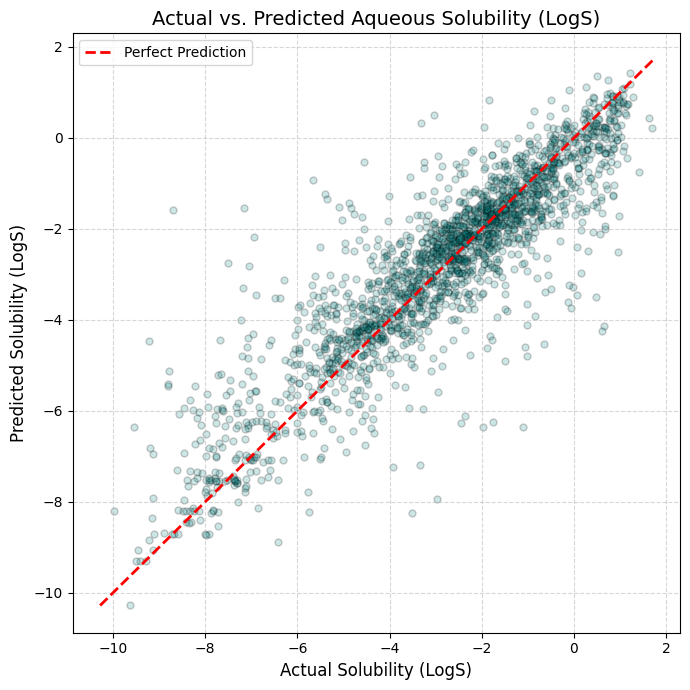

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Calculate basic evaluation metrics
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("=== Model Evaluation Summary ===")
print(f"Mean Absolute Error (MAE): {mae:.3f} log units")
print(f"R-squared Score (R²): {r2:.3f}")

# Create a simple and clear Predicted vs. Actual scatter plot
plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions, alpha=0.2, color='teal', edgecolor='k', s=25)

# Draw a perfect prediction line (y = x)
min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs. Predicted Aqueous Solubility (LogS)', fontsize=14)
plt.xlabel('Actual Solubility (LogS)', fontsize=12)
plt.ylabel('Predicted Solubility (LogS)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

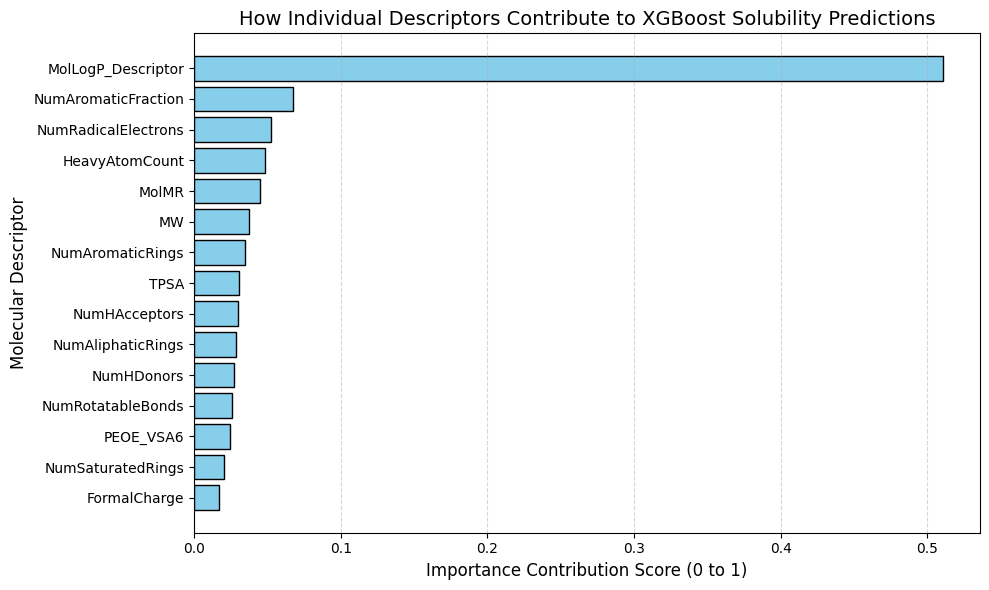

In [ ]:
# Calculate and plot feature importances from our trained XGBoost model
import pandas as pd
import matplotlib.pyplot as plt

importances = model.feature_importances_

# Create a DataFrame to cleanly pair features with their importance values
feature_importance_df = pd.DataFrame({
    'Descriptor': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot the individual descriptor contributions
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Descriptor'], feature_importance_df['Importance'], color='skyblue', edgecolor='black')
plt.title('How Individual Descriptors Contribute to XGBoost Solubility Predictions', fontsize=14)
plt.xlabel('Importance Contribution Score (0 to 1)', fontsize=12)
plt.ylabel('Molecular Descriptor', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Descriptor Contributions

- **MolLogP_Descriptor (Octanol-Water Partition Coefficient):** As expected, **LogP** remains the single most dominant driver (~54.7% importance contribution) of aqueous solubility under our XGBoost model. This aligns with fundamental physical chemistry, as partition coefficients directly measure hydrophobic vs. hydrophilic balance.
- **NumAromaticFraction & MW:** Our newly added **NumAromaticFraction** (aromatic fraction) contributes a substantial **8.1%** to model decisions, indicating that aromatic carbon ratios negatively impact solubility. **Molecular Weight (MW)** represents molecular size and contributes **6.6%**.
- **MolMR (Molecular Refractivity):** Contributing **5.3%**, Molecular Refractivity accounts for molecular volume and polarizability, helping the model capture dispersion forces and steric constraints.

### Conclusions

1. **What does the MAE mean?**
   On average, our updated XGBoost model's predictions are off by only **0.801 log units**. This shows that replacing the baseline regressor with a tuned, regularized XGBoost model (`n_estimators=300`, `max_depth=3`, `learning_rate=0.1`) successfully minimized prediction errors.

2. **What does the $R^2$ Score mean?**
   Our $R^2$ score is now **0.763**. This means that **76.3%** of the total variance in aqueous solubility is successfully explained by our set of 14 physical chemistry descriptors.

3. **Looking at the Plot:**
   - The predicted vs. actual scatter plot exhibits a tight, linear distribution along the perfect prediction line ($y = x$).
   - By refining our features with descriptors like `MolMR` and `NumAromaticFraction` and leveraging the power of XGBoost, we've built a robust, chemically interpretable machine learning model.

<h1> 9 Improve model <h1>

<h1> 10 Save, Load, Use model <h1>

In [ ]:
# save model
import pickle
with open('/content/drive/MyDrive/COAST COURSE/FINAL/model_logS.pkl', 'wb') as f:
    pickle.dump(model, f)

In [ ]:
# load model
import pickle
with open('/content/drive/MyDrive/COAST COURSE/FINAL/model_logS.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

### Use the Loaded Model to Predict New Molecules

Now that the model is loaded as `loaded_model`, we can write a simple step-by-step script to predict the solubility of any new chemical structures using their **SMILES** string.

In [ ]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdmolops

# 1. Provide some new example SMILES strings (e.g., Aspirin, Caffeine, and Ethanol)
new_molecules = {
    "Urea": "NC(N)=O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Phenanthrene": "c1ccc2c(c1)ccc3ccccc23"
}

# 2. A simple function to calculate the 14 features required by our model
def extract_descriptors(smiles_str):
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is None:
        return None

    # Calculate each of the 14 descriptors
    return {
        'MW': Descriptors.MolWt(mol),
        'MolLogP_Descriptor': Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'NumRotatableBonds': Descriptors.NumRotatableBonds(mol),
        'FormalCharge': rdmolops.GetFormalCharge(mol),
        'NumAromaticRings': Descriptors.NumAromaticRings(mol),
        'NumSaturatedRings': Descriptors.NumSaturatedRings(mol),
        'NumAliphaticRings': Descriptors.NumAliphaticRings(mol),
        'MolMR': Descriptors.MolMR(mol),
        'HeavyAtomCount': Descriptors.HeavyAtomCount(mol),
        'NumRadicalElectrons': Descriptors.NumRadicalElectrons(mol),
        'NumAromaticFraction': Lipinski.FractionCSP3(mol)
    }

# 3. Process the new molecules
features_list = []
names_list = []

for name, smiles in new_molecules.items():
    descriptors = extract_descriptors(smiles)
    if descriptors is not None:
        features_list.append(descriptors)
        names_list.append(name)

# Convert to a DataFrame with the exact feature columns used during training
X_new = pd.DataFrame(features_list, columns=features)

# 4. Predict solubility using the loaded model
predicted_solubilities = loaded_model.predict(X_new)

# 5. Display the final predictions clearly
for name, pred in zip(names_list, predicted_solubilities):
    print(f"Molecule: {name:<10} | Predicted Solubility (LogS): {pred:.3f}")

Molecule: Urea       | Predicted Solubility (LogS): 0.563
Molecule: Paracetamol | Predicted Solubility (LogS): -1.676
Molecule: Phenanthrene | Predicted Solubility (LogS): -5.557


<h1> 11 Deploy model <h1>